In [45]:
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

In [46]:
data_groups = pd.read_csv("./data/trials.csv")
data_opinion = pd.read_csv("./data/opinions.csv")
data_influence = pd.read_csv("./data/influence_chips.csv")

In [47]:
df_surgery = data_groups[data_groups["issue"] == "surgery"].drop(columns="issue")
df_surgery.head()

,trial_id,group_id,issue_order,group_size,opinion_unit,communication_network,consensus_pressure
1,D001-02,D001,2,2,percent,pair,high
3,D002-02,D002,2,2,percent,pair,high
4,D003-01,D003,1,2,percent,pair,high
6,D004-01,D004,1,2,percent,pair,high
8,D005-01,D005,1,2,percent,pair,high


In [48]:
df_influence = data_groups[data_groups["issue"] == "surgery"].drop(columns="issue")
df_surgery.head()

,trial_id,group_id,issue_order,group_size,opinion_unit,communication_network,consensus_pressure
1,D001-02,D001,2,2,percent,pair,high
3,D002-02,D002,2,2,percent,pair,high
4,D003-01,D003,1,2,percent,pair,high
6,D004-01,D004,1,2,percent,pair,high
8,D005-01,D005,1,2,percent,pair,high


In [49]:
df_surgery[df_surgery["group_id"] == "D001"][["group_id", "issue_order"]]

,group_id,issue_order
1,D001,2


In [51]:
df = df_surgery.merge(data_opinion, on="trial_id", how="left")
df = df.merge(data_influence, on="trial_id", how="left")
df

,trial_id,group_id,issue_order,group_size,opinion_unit,communication_network,consensus_pressure,member,opinion_initial,opinion_final,respondent,source,can_talk_directly,chips
0,D001-02,D001,2,2,percent,pair,high,A,60.0,60.0,A,A,0,12
1,D001-02,D001,2,2,percent,pair,high,A,60.0,60.0,A,B,1,8
2,D001-02,D001,2,2,percent,pair,high,A,60.0,60.0,B,A,1,11
3,D001-02,D001,2,2,percent,pair,high,A,60.0,60.0,B,B,0,9
4,D001-02,D001,2,2,percent,pair,high,B,70.0,70.0,A,A,0,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4347,Q050-05,Q050,5,4,percent,star,high,D,70.0,75.0,C,D,1,0
4348,Q050-05,Q050,5,4,percent,star,high,D,70.0,75.0,D,A,0,0
4349,Q050-05,Q050,5,4,percent,star,high,D,70.0,75.0,D,B,0,0
4350,Q050-05,Q050,5,4,percent,star,high,D,70.0,75.0,D,C,1,15


In [ ]:
sample_opinion_group = df[df["group_id"] == "Q050"][["member", "opinion_initial"]]
sample_opinion_group

,member,opinion_initial
364,A,80.0
365,B,70.0
366,C,75.0
367,D,70.0


(array([2., 0., 0., 0., 0., 1., 0., 0., 0., 1.]),
 array([70., 71., 72., 73., 74., 75., 76., 77., 78., 79., 80.]),
 <BarContainer object of 10 artists>)

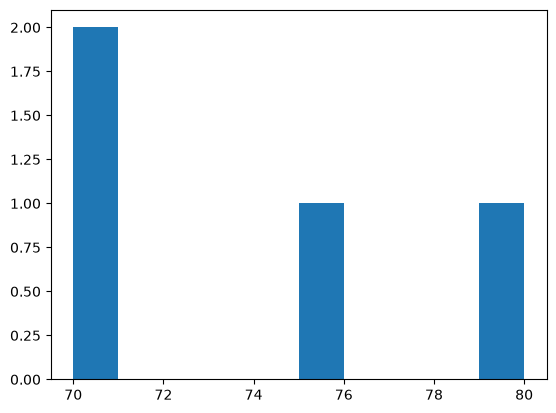

In [ ]:
plt.hist(sample_opinion_group["opinion_initial"], bins=10)

In [53]:
sample_influence_group = df[df["group_id"] == "Q050"][
    ["respondent", "source", "chips"]
]
sample_influence_group

,respondent,source,chips
4288,A,A,8
4289,A,B,0
4290,A,C,12
4291,A,D,0
4292,B,A,0
...,...,...,...
4347,C,D,0
4348,D,A,0
4349,D,B,0
4350,D,C,15


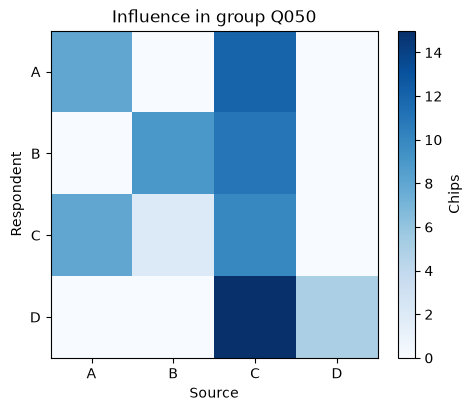

In [54]:
chips = data_influence.loc[data_influence["trial_id"].eq("Q050-05")]
matrix = chips.pivot(index="respondent", columns="source", values="chips")

fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
heatmap = ax.imshow(matrix, cmap="Blues", vmin=0)

ax.set_xticks(range(len(matrix.columns)), labels=matrix.columns)
ax.set_yticks(range(len(matrix.index)), labels=matrix.index)
ax.set(xlabel="Source", ylabel="Respondent", title="Influence in group Q050")
fig.colorbar(heatmap, ax=ax, label="Chips")
plt.show()